# Passo 1.1 — Teste de Fisher de longo prazo no Brasil

**Objetivo.** Testar a pedra angular do argumento neofisheriano (Cochrane / ALR 2026):
no longo prazo, $\pi = i - r$, com $r$ independente de $i$. Se verdade, $\pi$ e $i$ devem
ser **cointegradas** com vetor positivo — o coeficiente de $i$ na regressão de longo prazo
deve ser próximo de $+1$.

Se o vetor de longo prazo for negativo (como a visão convencional implica), a tese do ALR
cai já na primeira pedra.

**Testes:**
1. ADF em $\pi$, $i$ e $r = i - \pi$ (estacionariedade).
2. Engle-Granger de cointegração $\pi \sim i$.
3. Johansen VECM (vetor de cointegração explícito, com sinal).
4. Regressão de longo prazo $\pi = \alpha + \beta \cdot i$ (OLS + HAC), com teste de $\beta = 1$.

**Dados.** Lê os CSVs já cacheados em `cache_dados/`:
- `sgs_433.csv` — IPCA mensal
- `sgs_432.csv` — Selic meta diária (fallback `sgs_4189.csv`)


## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen

pd.set_option("display.float_format", lambda x: f"{x:.3f}")

# Caminho do cache — ajuste se seu notebook principal usa outro
CACHE_DIR = Path("cache_dados")
if not CACHE_DIR.exists():
    CACHE_DIR = Path("../cache_dados")
assert CACHE_DIR.exists(), f"Não achei cache_dados em {CACHE_DIR.resolve()}"
print(f"Cache: {CACHE_DIR.resolve()}")

Path("figs").mkdir(exist_ok=True)


Cache: C:\Users\Lenovo\Desktop\Desktop\Mestrado FGV\PoliticaMonetariaALR\files\cache_dados


## 2. Carrega séries do cache

In [2]:
def load_sgs(code):
    f = CACHE_DIR / f"sgs_{code}.csv"
    df = pd.read_csv(f)
    # colunas típicas: data, valor
    date_col = [c for c in df.columns if c.lower() in ("data", "date")][0]
    val_col  = [c for c in df.columns if c.lower() in ("valor", "value")][0]
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    df = df.dropna(subset=[date_col]).sort_values(date_col).set_index(date_col)
    s = pd.to_numeric(df[val_col], errors="coerce").dropna()
    s.name = f"sgs_{code}"
    return s

ipca_mensal = load_sgs(433)   # IPCA mensal (% a.m.)
try:
    selic = load_sgs(432)     # Selic meta (% a.a., diária)
except Exception:
    selic = load_sgs(4189)    # fallback: Selic over anualizada

print(f"IPCA mensal: {len(ipca_mensal)} obs, {ipca_mensal.index.min().date()} → {ipca_mensal.index.max().date()}")
print(f"Selic:       {len(selic)} obs, {selic.index.min().date()} → {selic.index.max().date()}")


IPCA mensal: 292 obs, 2002-01-01 → 2026-04-01
Selic:       8905 obs, 2002-01-01 → 2026-05-19


## 3. Constrói variáveis trimestrais (com IPCA 12m corrigido)

- $\pi$ = IPCA acumulado 12 meses (rolling 12m composta, pega o último do trimestre) — **igual ao oficial IBGE**.
- $i$ = Selic meta, média do trimestre.


In [3]:
# === DIAGNÓSTICO: o que tem dentro das séries? ===
print("IPCA MENSAL — amostra do índice:")
print(ipca_mensal.head(15))
print()
print("Tipo do índice:", type(ipca_mensal.index))
print("Freq inferida:", pd.infer_freq(ipca_mensal.index[:10]))
print()
print("Datas únicas por ano (primeiros 3 anos):")
amostra = ipca_mensal.loc["2002":"2004"]
print(f"  Total 2002-2004: {len(amostra)} obs")
print(f"  Datas: {amostra.index[:15].tolist()}")
print()
print("---")
print("SELIC — amostra:")
print(selic.head(10))
print()
print("Tipo do índice Selic:", type(selic.index))
print()
print("---")
print("Agora vou testar o resample passo a passo:")
teste1 = ipca_mensal.resample("QE").last()
print(f"  resample QE last() direto no IPCA mensal: {len(teste1)} obs")
print(f"  Primeiras datas: {teste1.index[:5].tolist()}")
print(f"  Últimas datas: {teste1.index[-5:].tolist()}")

IPCA MENSAL — amostra do índice:
data
2002-01-01   0.520
2002-02-01   0.360
2002-03-01   0.600
2002-04-01   0.800
2002-05-01   0.210
2002-06-01   0.420
2002-07-01   1.190
2002-08-01   0.650
2002-09-01   0.720
2002-10-01   1.310
2002-11-01   3.020
2002-12-01   2.100
2003-01-01   2.250
2003-02-01   1.570
2003-03-01   1.230
Name: sgs_433, dtype: float64

Tipo do índice: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Freq inferida: MS

Datas únicas por ano (primeiros 3 anos):
  Total 2002-2004: 36 obs
  Datas: [Timestamp('2002-01-01 00:00:00'), Timestamp('2002-02-01 00:00:00'), Timestamp('2002-03-01 00:00:00'), Timestamp('2002-04-01 00:00:00'), Timestamp('2002-05-01 00:00:00'), Timestamp('2002-06-01 00:00:00'), Timestamp('2002-07-01 00:00:00'), Timestamp('2002-08-01 00:00:00'), Timestamp('2002-09-01 00:00:00'), Timestamp('2002-10-01 00:00:00'), Timestamp('2002-11-01 00:00:00'), Timestamp('2002-12-01 00:00:00'), Timestamp('2003-01-01 00:00:00'), Timestamp('2003-02-01 00:00:00'), Time

In [4]:
# IPCA 12 meses — CORRIGIDO (data no fim do mês, não começo)
ipca = ipca_mensal.copy()
# Normaliza: joga pro fim do mês
ipca.index = ipca.index + pd.offsets.MonthEnd(0)

_frac = ipca / 100
ipca_12m_mensal = ((1 + _frac).rolling(12).apply(np.prod, raw=True) - 1) * 100
pi_trim = ipca_12m_mensal.resample("QE").last()
pi_trim.name = "pi"

# Selic — média trimestral (também normaliza)
sel = selic.copy()
sel.index = sel.index + pd.offsets.MonthEnd(0)
i_trim = sel.resample("QE").mean()
i_trim.name = "i"

df = pd.concat([pi_trim, i_trim], axis=1).dropna()
df["r_ex_post"] = df["i"] - df["pi"]

print(f"Amostra: {df.index.min().date()} a {df.index.max().date()}  ({len(df)} trimestres)")
print(f"Média π:          {df['pi'].mean():.3f}%")
print(f"Média i:          {df['i'].mean():.3f}%")
print(f"Média r (i - π):  {df['r_ex_post'].mean():.3f}%")
print()
print("Últimos 6 trimestres:")
print(df.tail(6).round(3))


Amostra: 2002-12-31 a 2026-06-30  (95 trimestres)
Média π:          6.079%
Média i:          11.804%
Média r (i - π):  5.725%

Últimos 6 trimestres:
              pi      i  r_ex_post
data                              
2025-03-31 5.477 13.061      7.584
2025-06-30 5.351 14.580      9.229
2025-09-30 5.172 15.000      9.828
2025-12-31 4.264 15.000     10.736
2026-03-31 4.143 14.964     10.821
2026-06-30 4.392 14.648     10.256


## 4. Teste (a) — ADF (estacionariedade)

Hipótese nula: a série tem raiz unitária (é não-estacionária).

**Interpretação:**
- Se $\pi$ e $i$ são I(1) (não-estacionárias) **e** $r = i - \pi$ é I(0) (estacionária),
  então $\pi$ e $i$ cointegram com vetor $[1, -1]$ — o que é **Fisher puro**.


In [5]:
def adf_report(serie, nome):
    res = adfuller(serie.dropna(), autolag="AIC")
    estat, p, lags, nobs, ic, _ = res
    print(f"  {nome:14s} | estat = {estat:+.3f} | p = {p:.3f} | lags = {lags} | n = {nobs}")
    print(f"  {'':14s}   crit 1%={ic['1%']:.3f}  5%={ic['5%']:.3f}  10%={ic['10%']:.3f}")
    v = "ESTACIONÁRIA (rejeita H0)" if p < 0.05 else "NÃO-ESTACIONÁRIA (aceita H0)"
    print(f"  {'':14s}   → {v}")
    print()
    return p

print("TESTES ADF — nível das séries")
print("-" * 60)
p_pi = adf_report(df["pi"], "π (IPCA 12m)")
p_i  = adf_report(df["i"],  "i (Selic)")
p_r  = adf_report(df["r_ex_post"], "r = i - π")


TESTES ADF — nível das séries
------------------------------------------------------------
  π (IPCA 12m)   | estat = -3.850 | p = 0.002 | lags = 10 | n = 84
                   crit 1%=-3.511  5%=-2.897  10%=-2.585
                   → ESTACIONÁRIA (rejeita H0)

  i (Selic)      | estat = -2.507 | p = 0.114 | lags = 2 | n = 92
                   crit 1%=-3.504  5%=-2.894  10%=-2.584
                   → NÃO-ESTACIONÁRIA (aceita H0)

  r = i - π      | estat = -2.669 | p = 0.080 | lags = 10 | n = 84
                   crit 1%=-3.511  5%=-2.897  10%=-2.585
                   → NÃO-ESTACIONÁRIA (aceita H0)



## 5. Teste (b) — Engle-Granger

Hipótese nula: **NÃO** há cointegração entre $\pi$ e $i$.


In [6]:
eg_stat, eg_p, eg_crit = coint(df["pi"], df["i"], autolag="AIC")
print(f"Engle-Granger:")
print(f"  Estatística: {eg_stat:+.3f}")
print(f"  p-valor:     {eg_p:.3f}")
print(f"  Críticos:    1%={eg_crit[0]:.3f}  5%={eg_crit[1]:.3f}  10%={eg_crit[2]:.3f}")
v_eg = "COINTEGRAM (rejeita H0)" if eg_p < 0.10 else "NÃO cointegram"
print(f"  → {v_eg}")


Engle-Granger:
  Estatística: -2.858
  p-valor:     0.148
  Críticos:    1%=-4.017  5%=-3.402  10%=-3.090
  → NÃO cointegram


## 6. Teste (c) — Johansen VECM

Posto de cointegração e **vetor** de cointegração explícito (dá o sinal).

**Interpretação:**
- Se rejeita $r = 0$, há pelo menos uma relação de cointegração.
- O vetor normalizado dá $\pi = \beta_{LR} \cdot i + \text{const}$.
- **$\beta_{LR} > 0$** → direção neofisheriana (ALR).
- **$\beta_{LR} < 0$** → direção convencional.


In [7]:
joh = coint_johansen(df[["pi", "i"]].values, det_order=0, k_ar_diff=1)
print("Johansen — Trace test")
print("-" * 60)
for k, (t, c) in enumerate(zip(joh.lr1, joh.cvt[:, 1])):
    hip = f"r ≤ {k}" if k > 0 else "r = 0"
    v_j = "rejeita" if t > c else "NÃO rejeita"
    print(f"  H0: {hip:7s} | trace = {t:.3f} | crit 5% = {c:.3f} | {v_j}")

# Vetor normalizado para π = 1 (pega parte real — autovetor pode vir complexo)
vec = np.real(joh.evec[:, 0])
vec_norm = vec / vec[0]
beta_lr_joh = -vec_norm[1]
print()
print(f"Vetor de cointegração normalizado (π, i): [{vec_norm[0]:+.3f}, {vec_norm[1]:+.3f}]")
print(f"→ Relação de longo prazo: π = {beta_lr_joh:+.3f} · i + const")
sinal = "POSITIVO — direção NEOFISHERIANA (ALR)" if beta_lr_joh > 0 else "NEGATIVO — direção CONVENCIONAL"
print(f"→ Sinal: {sinal}")


Johansen — Trace test
------------------------------------------------------------
  H0: r = 0   | trace = 56.644 | crit 5% = 15.494 | rejeita
  H0: r ≤ 1   | trace = 9.137 | crit 5% = 3.841 | rejeita

Vetor de cointegração normalizado (π, i): [+1.000, +0.459]
→ Relação de longo prazo: π = -0.459 · i + const
→ Sinal: NEGATIVO — direção CONVENCIONAL


## 7. Teste (d) — Regressão de longo prazo

$$\pi_t = \alpha + \beta \cdot i_t + \varepsilon_t$$

OLS com erros padrão HAC (Newey-West, 4 lags). Testamos a **hipótese neofisheriana forte**: $H_0: \beta = 1$.


In [8]:
X = sm.add_constant(df["i"])
y = df["pi"]
mod = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

alpha  = mod.params["const"]
beta   = mod.params["i"]
p_beta = mod.pvalues["i"]

print(f"α (constante):  {alpha:+.3f}")
print(f"β (coef de i):  {beta:+.3f}   (p = {p_beta:.3f})")
print(f"R²:             {mod.rsquared:.3f}")
print()

# H0: β = 1 (Fisher puro)
tt = mod.t_test("i = 1")
print(f"Teste H0: β = 1 (hipótese neofisheriana forte)")
print(f"  t = {float(np.ravel(tt.tvalue)[0]):+.3f} | p = {float(np.ravel(tt.pvalue)[0]):.3f}")
v_f1 = "COMPATÍVEL com β=1 (não rejeita)" if float(np.ravel(tt.pvalue)[0]) > 0.10 else "INCOMPATÍVEL com β=1 (rejeita)"
print(f"  → {v_f1}")
print()
print(f"Sinal de β: {'POSITIVO (direção ALR)' if beta > 0 else 'NEGATIVO (direção convencional)'}")


α (constante):  +2.266
β (coef de i):  +0.323   (p = 0.016)
R²:             0.297

Teste H0: β = 1 (hipótese neofisheriana forte)
  t = -5.030 | p = 0.000
  → INCOMPATÍVEL com β=1 (rejeita)

Sinal de β: POSITIVO (direção ALR)


## 8. Veredito consolidado

In [9]:
print("=" * 70)
print("VEREDITO — PASSO 1.1 (Fisher de longo prazo)")
print("=" * 70)
print(f"  π não-estacionária?             {'sim' if p_pi > 0.05 else 'não'}  (p={p_pi:.3f})")
print(f"  i não-estacionária?             {'sim' if p_i > 0.05 else 'não'}  (p={p_i:.3f})")
print(f"  r = (i-π) estacionária?         {'sim' if p_r < 0.05 else 'não'}  (p={p_r:.3f})")
print(f"  Engle-Granger: cointegram?      {'sim' if eg_p < 0.10 else 'não'}  (p={eg_p:.3f})")
print(f"  Johansen: ≥1 vetor?             {'sim' if joh.lr1[0] > joh.cvt[0,1] else 'não'}")
print(f"  β longo prazo (Johansen):       {float(beta_lr_joh):+.3f}")
print(f"  β longo prazo (OLS/HAC):        {beta:+.3f}  (p={p_beta:.3f})")
print(f"  H0: β = 1 rejeitada?            {'sim' if float(np.ravel(tt.pvalue)[0]) < 0.10 else 'não'}  (p={float(np.ravel(tt.pvalue)[0]):.3f})")
print()
print("Leitura:")
if beta > 0 and eg_p < 0.10:
    print("  Há cointegração com β POSITIVO — compatível com a direção")
    print("  neofisheriana de Cochrane/ALR. Quão literal (β=1) depende do teste H0.")
elif beta < 0:
    print("  β NEGATIVO — direção CONVENCIONAL. A pedra angular da tese de ALR")
    print("  (neofisherianismo de longo prazo) não se sustenta nos dados brasileiros.")
else:
    print("  Evidência mista — ver detalhes de cada teste.")


VEREDITO — PASSO 1.1 (Fisher de longo prazo)
  π não-estacionária?             não  (p=0.002)
  i não-estacionária?             sim  (p=0.114)
  r = (i-π) estacionária?         não  (p=0.080)
  Engle-Granger: cointegram?      não  (p=0.148)
  Johansen: ≥1 vetor?             sim
  β longo prazo (Johansen):       -0.459
  β longo prazo (OLS/HAC):        +0.323  (p=0.016)
  H0: β = 1 rejeitada?            sim  (p=0.000)

Leitura:
  Evidência mista — ver detalhes de cada teste.


## 9. Visualização

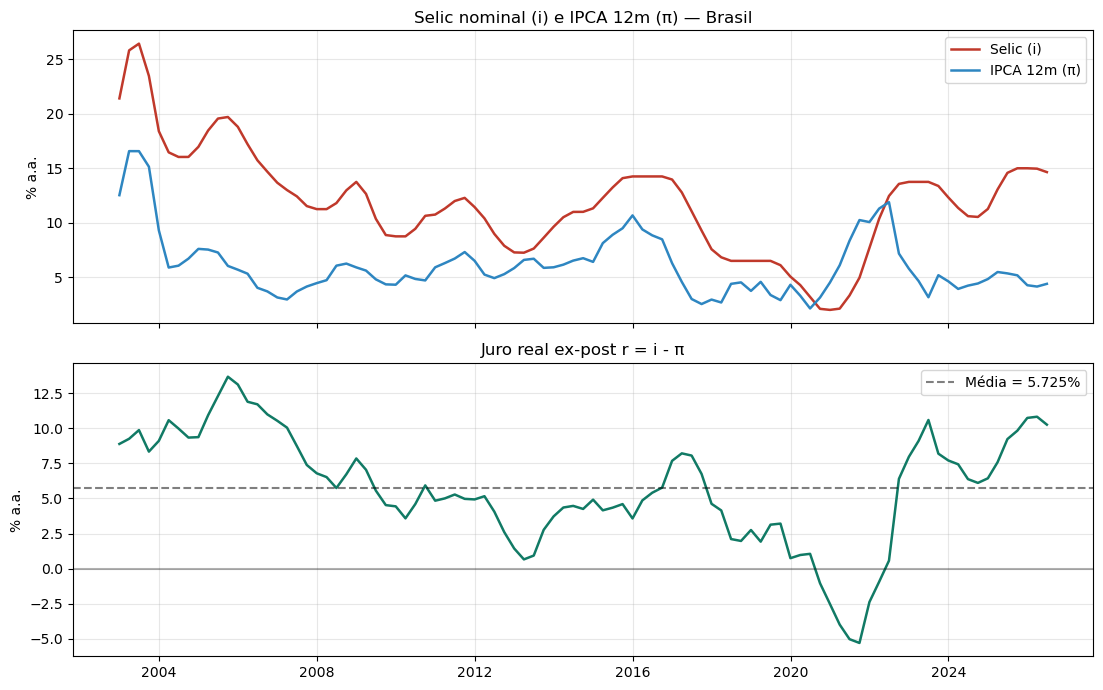

Figura salva em figs/fig_fisher_lr.png


In [10]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

ax1 = axes[0]
ax1.plot(df.index, df["i"],  label="Selic (i)",    lw=1.8, color="#C0392B")
ax1.plot(df.index, df["pi"], label="IPCA 12m (π)", lw=1.8, color="#2E86C1")
ax1.set_ylabel("% a.a.")
ax1.set_title("Selic nominal (i) e IPCA 12m (π) — Brasil")
ax1.legend(loc="upper right")
ax1.grid(alpha=0.3)

ax2 = axes[1]
ax2.plot(df.index, df["r_ex_post"], color="#117A65", lw=1.8)
ax2.axhline(df["r_ex_post"].mean(), color="k", ls="--", alpha=0.5,
            label=f"Média = {df['r_ex_post'].mean():.3f}%")
ax2.axhline(0, color="k", alpha=0.3)
ax2.set_ylabel("% a.a.")
ax2.set_title("Juro real ex-post r = i - π")
ax2.legend(loc="upper right")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figs/fig_fisher_lr.png", dpi=120, bbox_inches="tight")
plt.show()
print("Figura salva em figs/fig_fisher_lr.png")


## 10. Scatter π vs i com reta de regressão

Visualização do coeficiente $\beta$ da regressão de longo prazo.


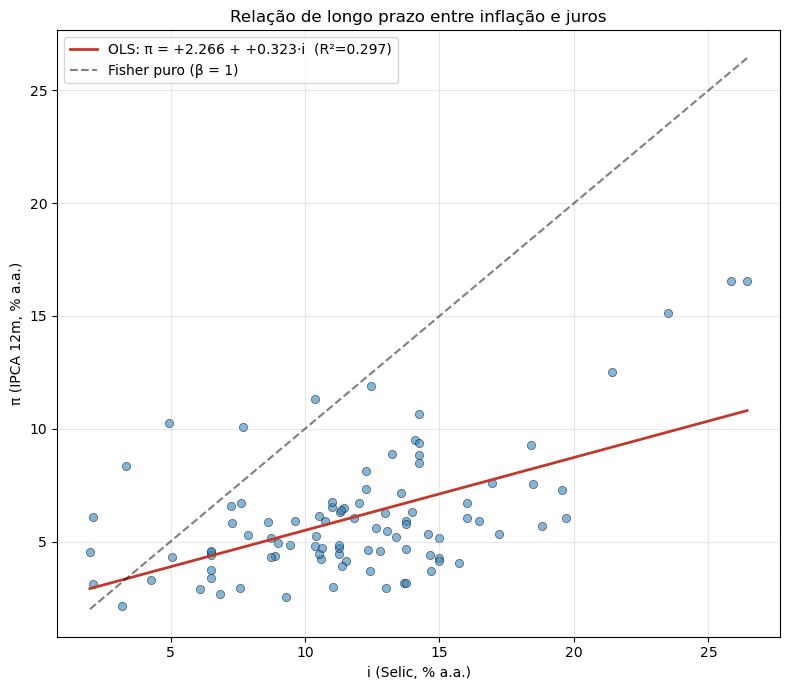

Figura salva em figs/fig_fisher_scatter.png


In [11]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(df["i"], df["pi"], s=35, alpha=0.6, color="#2E86C1", edgecolor="k", lw=0.5)

# reta de regressão
xs = np.linspace(df["i"].min(), df["i"].max(), 100)
ys = alpha + beta * xs
ax.plot(xs, ys, color="#C0392B", lw=2,
        label=f"OLS: π = {alpha:+.3f} + {beta:+.3f}·i  (R²={mod.rsquared:.3f})")

# reta 45° (Fisher puro)
ax.plot(xs, xs, color="k", ls="--", alpha=0.5, label="Fisher puro (β = 1)")

ax.set_xlabel("i (Selic, % a.a.)")
ax.set_ylabel("π (IPCA 12m, % a.a.)")
ax.set_title("Relação de longo prazo entre inflação e juros")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figs/fig_fisher_scatter.png", dpi=120, bbox_inches="tight")
plt.show()
print("Figura salva em figs/fig_fisher_scatter.png")
